# Кластеризация и техники понижения размерности. Часть I

## K-Means и EM-алгоритм: практика

In [2]:
#Загрузка необходимых библиотек
import numpy as np 
import pandas as pd

#Загружаем data frame
df_teens = pd.read_csv('data/snsdata.csv')

display(df_teens.head())
display(df_teens.info())

,gradyear,gender,age,friends,basketball,football,soccer,softball,volleyball,swimming,...,blonde,mall,shopping,clothes,hollister,abercrombie,die,death,drunk,drugs
0,2006,M,18.982,7,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,2006,F,18.801,0,0,1,0,0,0,0,...,0,1,0,0,0,0,0,0,0,0
2,2006,M,18.335,69,0,1,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
3,2006,F,18.875,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,2006,NaN,18.995,10,0,0,0,0,0,0,...,0,0,2,0,0,0,0,0,1,1


<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 40 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   gradyear      30000 non-null  int64  
 1   gender        27276 non-null  str    
 2   age           24914 non-null  float64
 3   friends       30000 non-null  int64  
 4   basketball    30000 non-null  int64  
 5   football      30000 non-null  int64  
 6   soccer        30000 non-null  int64  
 7   softball      30000 non-null  int64  
 8   volleyball    30000 non-null  int64  
 9   swimming      30000 non-null  int64  
 10  cheerleading  30000 non-null  int64  
 11  baseball      30000 non-null  int64  
 12  tennis        30000 non-null  int64  
 13  sports        30000 non-null  int64  
 14  cute          30000 non-null  int64  
 15  sex           30000 non-null  int64  
 16  sexy          30000 non-null  int64  
 17  hot           30000 non-null  int64  
 18  kissed        30000 non-null  int64  

None

### Задание 4.1

Мы будем реализовывать алгоритм только на признаках, которые заключают в себе ключевые слова, встречающиеся в сообщениях подростка. Удалите все остальные признаки. Какова размерность вашего текущего набора данных?

In [3]:
# Удаляем ненужные признаки (первые 4 колонки)
df_teens = df_teens.drop(columns=['gradyear', 'gender', 'age', 'friends'])

# Выводим размерность текущего набора данных (количество строк и столбцов)
print(f"Размерность набора данных: {df_teens.shape}")

Размерность набора данных: (30000, 36)


### Задание 4.2
Теперь нормализуйте данные с помощью StandardScaler(). Для получившейся матрицы нормализованных признаков выведите самое первое значение в самой первой строке (X_norm[0][0]). Ответ округлите до двух знаков после точки-разделителя.

In [4]:
from sklearn.preprocessing import StandardScaler

# 1. Инициализируем scaler
scaler = StandardScaler()

# 2. Применяем нормализацию ко всему датасету
X_norm = scaler.fit_transform(df_teens)

# 3. Выводим самое первое значение (первая строка, первый столбец)
first_value = X_norm[0][0]

print(f"Самое первое значение в матрице: {round(first_value, 2)}")

Самое первое значение в матрице: -0.33


### Задание 4.3
Реализуйте алгоритм k-means c девятью кластерами. В качестве значения параметра random_state возьмите число 42. Выведите получившееся значение инерции (model.inertia_). Ответ округлите до двух знаков после точки-разделителя.


In [16]:
from sklearn.cluster import KMeans

# 1. Инициализируем KMeans с 9 кластерами и random_state=42
kmeans = KMeans(n_clusters=9, random_state=42)

# 2. Обучаем модель на нормализованных данных
kmeans.fit(X_norm)

# 3. Выводим инерцию, округленную до двух знаков
print(f"Значение инерции: {round(kmeans.inertia_, 2)}")

Значение инерции: 856276.7


### Задание 4.4
Сколько подростков относится к наиболее многочисленному кластеру?

А сколько — к самому малочисленному?

In [18]:
# Считаем количество объектов в каждом кластере
cluster_counts = pd.Series(kmeans.labels_).value_counts()

# Выводим результаты
print("Количество подростков в каждом кластере:")
print(cluster_counts.sort_index())

print(f"\nНаиболее многочисленный кластер (№{cluster_counts.idxmax()}): {cluster_counts.max()} человек")
print(f"Самый малочисленный кластер (№{cluster_counts.idxmin()}): {cluster_counts.min()} человек")

Количество подростков в каждом кластере:
0     2201
1    19599
2     4284
3      902
4      941
5      851
6        1
7      467
8      754
Name: count, dtype: int64

Наиболее многочисленный кластер (№1): 19599 человек
Самый малочисленный кластер (№6): 1 человек


### Задание 4.5 
1. Мы выделили девять кластеров, но, возможно, это далеко не оптимальное количество. Давайте попробуем применить разные методы для нахождения числа кластеров. Будем выбирать количество кластеров из диапазона от 3 до 9.

Для начала примените метод локтя. Каким в этом случае будет оптимальное число кластеров? Если оно не идентифицируется однозначно, запишите количество кластеров, при котором достигается наименьшая инерция.

2. Теперь попробуйте подобрать оптимальное количество кластеров с помощью коэффициента силуэта. Каким оно будет?

Если невозможно однозначно определить количество кластеров, при котором достигается максимальное значение коэффициента силуэта, выберите наименьшее количество кластеров из подходящих.

Кластеров: 3, Инерция: 994114.72
Кластеров: 4, Инерция: 965041.28
Кластеров: 5, Инерция: 943134.13
Кластеров: 6, Инерция: 917113.38
Кластеров: 7, Инерция: 899316.34
Кластеров: 8, Инерция: 872318.48
Кластеров: 9, Инерция: 856276.70


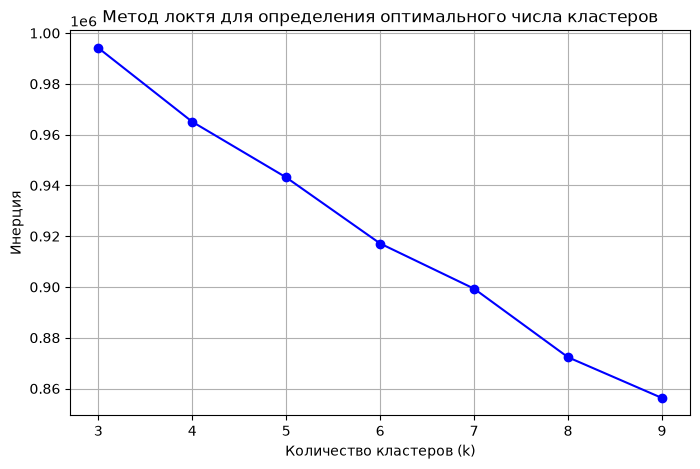

In [20]:
import matplotlib.pyplot as plt

inertias = []
K_range = range(3, 10)

for k in K_range:
    kmeans_temp = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans_temp.fit(X_norm)
    inertias.append(kmeans_temp.inertia_)
    print(f"Кластеров: {k}, Инерция: {kmeans_temp.inertia_:.2f}")

# Строим график
plt.figure(figsize=(8, 5))
plt.plot(K_range, inertias, marker='o', linestyle='-', color='b')
plt.title('Метод локтя для определения оптимального числа кластеров')
plt.xlabel('Количество кластеров (k)')
plt.ylabel('Инерция')
plt.xticks(K_range)
plt.grid(True)
plt.show()

Кластеров: 3, Silhouette Score: 0.3254
Кластеров: 4, Silhouette Score: 0.3273
Кластеров: 5, Silhouette Score: 0.3167
Кластеров: 6, Silhouette Score: 0.2906
Кластеров: 7, Silhouette Score: 0.2848
Кластеров: 8, Silhouette Score: 0.2518
Кластеров: 9, Silhouette Score: 0.2519


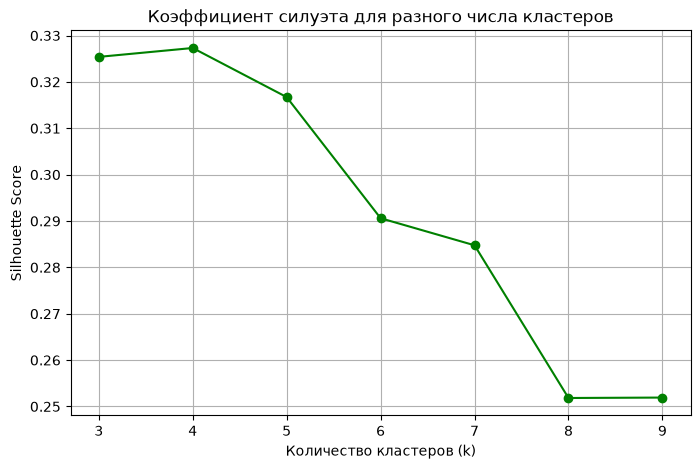

In [21]:
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

silhouette_scores = []
K_range = range(3, 10)

for k in K_range:
    kmeans_temp = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans_temp.fit_predict(X_norm)
    
    # Считаем коэффициент силуэта
    score = silhouette_score(X_norm, labels)
    silhouette_scores.append(score)
    print(f"Кластеров: {k}, Silhouette Score: {score:.4f}")

# Строим график
plt.figure(figsize=(8, 5))
plt.plot(K_range, silhouette_scores, marker='o', linestyle='-', color='g')
plt.title('Коэффициент силуэта для разного числа кластеров')
plt.xlabel('Количество кластеров (k)')
plt.ylabel('Silhouette Score')
plt.xticks(K_range)
plt.grid(True)
plt.show()

### Задание 4.6
Мы будем использовать результаты, полученные в предыдущем задании с помощью коэффициента силуэта.

Реализуйте сегментацию подростков на выбранном количестве кластеров.

Для каждого кластера составьте топ-10 самых частых слов, назовём их ключевыми. Для этого сгруппируйте данные по кластерам, в каждом кластере вычислите среднее по каждому признаку, отсортируйте данные по убыванию и выделите первые 10 строк.

Найдите среди ключевых слов те, которые характерны для каждого кластера, то есть встречаются в каждом из них.

In [22]:
# 1. Обучаем K-Means с 3 кластерами
kmeans_final = KMeans(n_clusters=3, random_state=42, n_init=10)
kmeans_final.fit(X_norm)

# 2. Добавляем метки кластеров в наш датафрейм (до нормализации, чтобы сохранить исходные частоты)
df_teens_clustered = df_teens.copy()
df_teens_clustered['cluster'] = kmeans_final.labels_

# 3. Группируем по кластерам и считаем средние значения
# Так как признаки — это частоты слов, среднее покажет, насколько часто слово встречается в кластере
cluster_means = df_teens_clustered.groupby('cluster').mean()

# 4. Для каждого кластера находим топ-10 слов
top_10_words = {}
for cluster_id in cluster_means.index:
    # Сортируем признаки по убыванию среднего значения и берем первые 10
    top_words = cluster_means.loc[cluster_id].sort_values(ascending=False).head(10)
    top_10_words[cluster_id] = top_words.index.tolist()
    
    print(f"\n--- Топ-10 слов для кластера {cluster_id} ---")
    for word, val in top_words.items():
        print(f"{word}: {val:.2f}")


--- Топ-10 слов для кластера 0 ---
music: 0.58
god: 0.33
dance: 0.25
band: 0.24
hair: 0.20
shopping: 0.19
cute: 0.18
rock: 0.16
soccer: 0.15
football: 0.15

--- Топ-10 слов для кластера 1 ---
music: 1.05
dance: 0.99
shopping: 0.93
god: 0.89
cute: 0.79
hair: 0.73
church: 0.67
basketball: 0.67
mall: 0.66
football: 0.60

--- Топ-10 слов для кластера 2 ---
hair: 3.23
sex: 2.43
music: 2.26
kissed: 1.57
die: 1.21
rock: 1.11
god: 1.00
band: 0.97
dance: 0.97
drugs: 0.95


### Задание 4.7
Итак, с k-means мы потренировались — теперь перейдём к EM-алгоритму.

Реализуйте EM-алгоритм (GaussianMixture) для такого же количества кластеров, как и в предыдущем задании. В качестве значения параметра random_state возьмите число 42.

Сколько подростков алгоритм отнёс к самому многочисленному кластеру?

In [29]:
from sklearn.mixture import GaussianMixture
import pandas as pd

# 1. Инициализируем и обучаем модель
# n_components — это аналог n_clusters в K-Means
gmm = GaussianMixture(n_components=3, random_state=42)
gmm.fit(X_norm)

# 2. Получаем метки кластеров для каждого объекта
labels_gmm = gmm.predict(X_norm)

# 3. Считаем, сколько объектов в каждом кластере
cluster_counts_gmm = pd.Series(labels_gmm).value_counts()

# 4. Выводим результаты
print("Количество подростков в каждом кластере (GMM):")
print(cluster_counts_gmm)

print(f"\nСамый многочисленный кластер: {cluster_counts_gmm.max()} человек")

Количество подростков в каждом кластере (GMM):
0    20670
2     6456
1     2874
Name: count, dtype: int64

Самый многочисленный кластер: 20670 человек


### Задание 4.8
В одном из кластеров оказался всего один человек. Давайте узнаем, что это за подросток и чем он(а) интересуется.

Отметьте три слова, которые чаще всего встречаются в сообщениях этого подростка:




## DBSCAN